# calc_02c. Forced response: probability ratios (calculations)

For each single-forcing experiment, what has changed relative to hist-nat (natural forcing only), and is it more than natural variability can produce? This notebook works out how much more often a warm or a cold season comes, and how much of that the shift of the mean alone gives, on the maps and for regional means. The forced response is in three notebooks, so that none grows too big to open: calc_02a, the distribution and its width; calc_02b, the mean; calc_02c, the probability ratios. Run them in that order: calc_02b opens the SAM phases and the rolling quantiles calc_02a saved, and calc_02c the SAM phases, calc_02a's quantiles and calc_02b's means. Notebooks plot_03a to plot_06 draw the figures from the saved results.

| Section | What it computes | Saved in `RESULTS_DIR` as |
|---|---|---|
| SAM phases | each season's phase, as notebook calc_02a saved it (`sam_final_masks`) | |
| 1. Regional means | every member's regional means, and the regional change in every 5th percentile | `regional_seasonal`, `regional_quantile_curve` |
| 2. Probability ratios | how much more often a season beyond hist-nat's 95th (warm) or 5th (cold) percentile, on maps and for the regions; on maps by SAM phase | `probability_ratio`, `probability_ratio_regional`, `sam_probability_ratio` |
| 3. Shift-only ratio | the probability ratio the shift of the mean alone would give, next to section 2's; on maps by SAM phase | `probability_ratio_shift_only`, `probability_ratio_shift_only_regional`, `sam_probability_ratio_shift_only` |

Every section starts with how its method works, shown at one grid point, before running it everywhere.

**Following the data.** Each cell does one step and ends with what it made, so Jupyter shows it. Before each method figure comes a **quick look**: the arrays the figure is given, picked out and shown, then drawn plainly with xarray's own `.plot`, all of the code here in the notebook. The method figure after it is given exactly those arrays. Names end in their type: `_tree` (DataTree), `_ds` (Dataset), `_da` (DataArray), `_arr` (numpy array), `_df` (DataFrame).

**Notation.** $x_{m,y}$ is one season's mean in member $m$ and year $y$, at one grid point; an ensemble has $M$ members. $Q_p(\cdot)$ is the $p$ quantile of a set of values. "The final years" are the last $L = 21$ years of the record (`config.WINDOW`): 1993–2013. The tests measure every change from hist-nat over the same years.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
from plotting_modules import formatting
from plotting_modules.constants import FORCING_COLORS
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from extant import config, datatree, preprocessing as pp, zonal
from extant.config import ALPHA, QUANTILES, WINDOW
from extant import quantiles as qc, response_change as rc, significance as sig
from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from extant.plots import zonal as zp
from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

The settings every notebook shares are in `extant/config.py` (`ALPHA`, `QUANTILES`, `WINDOW`). Only this notebook's own choices are here.

In [ ]:
VARIABLE = config.VARIABLES['tas']

#(t): One experiment at one grid point, for the method figures (whose bootstrap draws more trials)
DEMO_MODEL = config.PLOT_SEL['model']
DEMO_EXPERIMENT = config.PLOT_SEL['experiment']
DEMO_POINT = {'season': 'DJF', 'lat': -75.0, 'lon': -180.0}
DEMO_SEL = dict(model=DEMO_MODEL, season=DEMO_POINT['season'])
DEMO_LATLON = dict(lat=DEMO_POINT['lat'], lon=DEMO_POINT['lon'], method='nearest')
DEMO_TRIALS = 10_000

#(t): The regions of the regional means (sections 1 to 3): the boxes of notebook calc_03a, observed_change.REGIONS
REGIONS = oc.REGIONS

#(t): The probability ratios (sections 2 and 3): hist-nat's chance of a warm or a cold season (0.05: beyond its
#(t): 95th or 5th percentile; 0.10 checks it), and the bootstrap's trials
CHANCES = pr.CHANCES
PR_TRIALS = 1000

In [4]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch; and the sample in
#(t): this repository
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SAMPLE_DIR = Path('../tests/data')
SCRATCH_DIR, SAMPLE_DIR

(PosixPath('/work/scratch-pw4/aborow/ExtAnt'), PosixPath('../tests/data'))

## Dask Cluster

The heavy steps run on a Dask Gateway cluster on JASMIN. `jasmin.stop_all(gateway)` stops every cluster left over from an earlier kernel.

In [5]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/5e7a7a016911447497ff6fc035ce801f/status,


## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means as a DataTree, `/<model>/<experiment>`, on member × year × season × lat × lon, in analysis units) and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around `config.POINT` in `tests/data`, through the same pre-processing as notebook calc_01.

In [6]:
#(t): The sample's files: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [7]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [8]:
#(t): Each file of config.MAIN_EXPERIMENTS opened, as a DataTree /<model>/<experiment>
lesfmip_sample_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                             for path, (model, experiment) in zip(sample_files, sample_names)
                                             if experiment in config.MAIN_EXPERIMENTS})

In [9]:
#(t): Seasonal means in analysis units, through the same pre-processing as notebook calc_01
lesfmip_season_tree = pp.seasonal_tree(lesfmip_sample_tree, VARIABLE.name).compute()

In [10]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`.

In [11]:
#(t): The seasonal store notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [12]:
#(t): Opened lazily
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [13]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [14]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_season_tree.filter(lambda node: node.name in config.MAIN_EXPERIMENTS)

In [15]:
lesfmip_season_tree = lesfmip_season_tree.persist()
wait(lesfmip_season_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

## First Look

The two ensembles every method figure below starts from: one season at the demonstration point, `DEMO_EXPERIMENT` and hist-nat, each on (member, year), as in notebook calc_02a (which draws every member of each experiment there).

In [24]:
#(t): One model at the demonstration point, every experiment and season, loaded into memory
demo_tree = lesfmip_season_tree[DEMO_MODEL].sel(**DEMO_LATLON).load()

In [25]:
#(t): The two ensembles every method figure below starts from, one season on (member, year): DEMO_EXPERIMENT
demo_experiment_da = demo_tree[DEMO_EXPERIMENT][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [26]:
#(t): and hist-nat
demo_histnat_da = demo_tree['hist-nat'][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [27]:
#(t): The final WINDOW years of both, on (member, year): what the tests below compare. DEMO_EXPERIMENT's
demo_experiment_final_da = demo_experiment_da.isel(year=slice(-WINDOW, None))
demo_experiment_final_da

<xarray.DataArray 'tas' (member: 65, year: 21)> Size: 5kB
-4.085 -3.57 -3.189 -3.098 -5.389 -1.828 ... -2.439 -6.07 -2.589 -3.868 -4.345
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [28]:
#(t): and hist-nat's
demo_histnat_final_da = demo_histnat_da.isel(year=slice(-WINDOW, None))
demo_histnat_final_da

<xarray.DataArray 'tas' (member: 50, year: 21)> Size: 4kB
-4.043 -3.745 -3.426 -6.0 -6.079 -4.988 ... -7.633 -5.49 -5.762 -5.217 -4.376
Coordinates:
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013

## SAM Phases

Every *By SAM phase* subsection redoes its result with the seasons of one phase of the Southern Annular Mode alone. The phases are notebook calc_02a's (*SAM Phases*, where they are made and explained): each season of each member, negative, neutral or positive against hist-nat's terciles of the index over the final $L$ years, opened here from its save.

In [ ]:
#(t): Each season's SAM phase over the final WINDOW years, as notebook calc_02a saved it: True in one of the three
#(t): along 'phase', every member, year and season, /<model>/<experiment>
sam_final_masks_path = RESULTS_DIR / 'sam_final_masks.zarr'
sam_final_masks_path

In [ ]:
sam_final_masks_tree = xr.open_datatree(sam_final_masks_path, engine='zarr').load()

In [ ]:
#(t): /<model>/<experiment> of every node with both the index and temperature: the ones the masks were made for
sam_both_paths = {node.relative_to(sam_final_masks_tree) for node in sam_final_masks_tree.leaves if node.data_vars}
sorted(sam_both_paths)

## The Final Years

Every result here compares the final $L$ years of each experiment with hist-nat's over the same years.

In [ ]:
#(t): The final WINDOW years of every experiment
lesfmip_final_tree = lesfmip_season_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): Every experiment's model's hist-nat over the same final years, in a tree shaped like lesfmip_final_tree
hist_nat_final_tree = datatree.hist_nat_like(lesfmip_final_tree)

## 1. Regional Means

The regional figures of notebook plot_06, and the regional probability ratios of sections 2 and 3, use area means over regions (`REGIONS`, the boxes notebook calc_03a uses), weighted by the cosine of latitude:

$$
\bar{x}^{R}_{m,y} = \frac{\sum_{(\varphi, \lambda) \in R} \cos\varphi \; x_{m,y}(\varphi, \lambda)}{\sum_{(\varphi, \lambda) \in R} \cos\varphi}.
$$

A region with no grid points in the data is NaN (the sample has only its 3×3 block, in East Antarctica). The quantile curves are the regional means of each grid point's change in every 5th percentile (notebook calc_02a, section 3), as the Antarctic-mean curve is.

In [298]:
#(t): The regions: name -> the box selected on the grid
REGIONS

{'Antarctica (90–65°S)': {'lat': slice(-90, -65, None)},
 'Antarctic Peninsula': {'lat': slice(-75, -62.5, None),
  'lon': slice(-75, -55, None)},
 'Southern Ocean (65–50°S)': {'lat': slice(-65, -50, None)}}

In [299]:
#(t): Every member's regional means, every year: a tree like lesfmip_season_tree, with region in place of lat and lon
regional_season_tree = oc.regional_means(lesfmip_season_tree, REGIONS)
regional_season_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (region: 3, member: 63, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 992kB dask.array<chunksize=(1, 63, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (region: 3, member: 45, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 708kB dask.array<chunksize=(1, 45, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (region: 3, member: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 315kB dask.array<chunksize=(1, 20, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (region: 3, member: 45, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 708kB dask.array<chunksize=(1, 45, 164, 4), meta=np.ndarray>
│   └── Group: /GISS-E2-1-G/hist-totalO3
│           Dimensions:  (region: 3, member: 40, year: 164, season: 4)
│           Coordinates:
│             * member   (member) object 320B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│           Data variables:
│               tas      (region, member, year, season) float64 630kB dask.array<chunksize=(1, 40, 164, 4), meta=np.ndarray>
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (region: 3, member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 787kB dask.array<chunksize=(1, 50, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (region: 3, member: 10, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851

In [ ]:
%%time
#(t): Computed once: sections 2 and 3 use it, and notebook plot_06 opens it
regional_season_tree = regional_season_tree.compute()
regional_season_tree

In [301]:
#(t): Saved for notebooks plot_03 to plot_06
regional_seasonal_path = RESULTS_DIR / 'regional_seasonal.zarr'
regional_season_tree.to_zarr(regional_seasonal_path, mode='w')
regional_seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_seasonal.zarr')

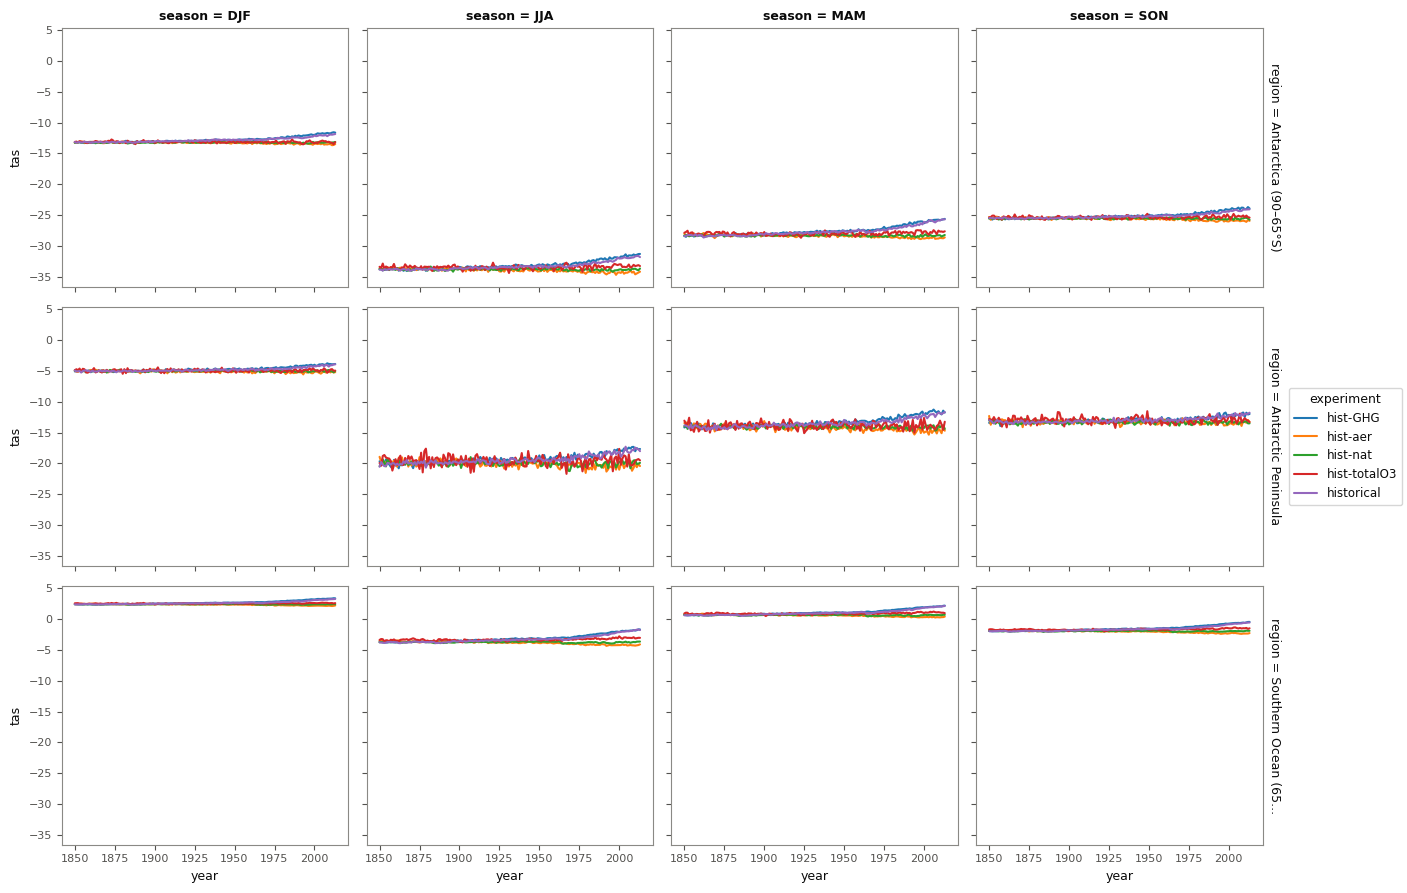

In [302]:
#(t): Quick look: DEMO_MODEL's ensemble means, one line per experiment, one panel per region and season
regional_demo_mean_ds = datatree.tree_to_dataset(regional_season_tree[DEMO_MODEL].mean('member'), dims=['experiment'])
regional_demo_mean_ds[VARIABLE.name].plot(x='year', hue='experiment', row='region', col='season');

In [ ]:
#(t): Every experiment's quantiles over its final years, and hist-nat's, as notebook calc_02a saved them (its section 3)
final_quantiles_path = RESULTS_DIR / 'final_quantiles.zarr'
hist_nat_final_quantiles_path = RESULTS_DIR / 'hist_nat_final_quantiles.zarr'
final_quantiles_path, hist_nat_final_quantiles_path

In [ ]:
final_q_da = xr.open_zarr(final_quantiles_path)[VARIABLE.name].load()

In [ ]:
hist_nat_q_da = xr.open_zarr(hist_nat_final_quantiles_path)[VARIABLE.name].load()

In [155]:
#(t): The change in every quantile: final years minus hist-nat's over the same years
quantile_change_da = final_q_da - hist_nat_q_da

In [ ]:
#(t): The change in every 5th percentile (above), averaged over each region
regional_quantile_curve_da = oc.regional_means(quantile_change_da, REGIONS).rename('regional_quantile_curve')
regional_quantile_curve_da

In [304]:
#(t): Saved for notebooks plot_03 to plot_06
regional_quantile_curve_path = RESULTS_DIR / 'regional_quantile_curve.zarr'
regional_quantile_curve_da.to_dataset(name='regional_quantile_curve').to_zarr(regional_quantile_curve_path, mode='w')
regional_quantile_curve_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_quantile_curve.zarr')

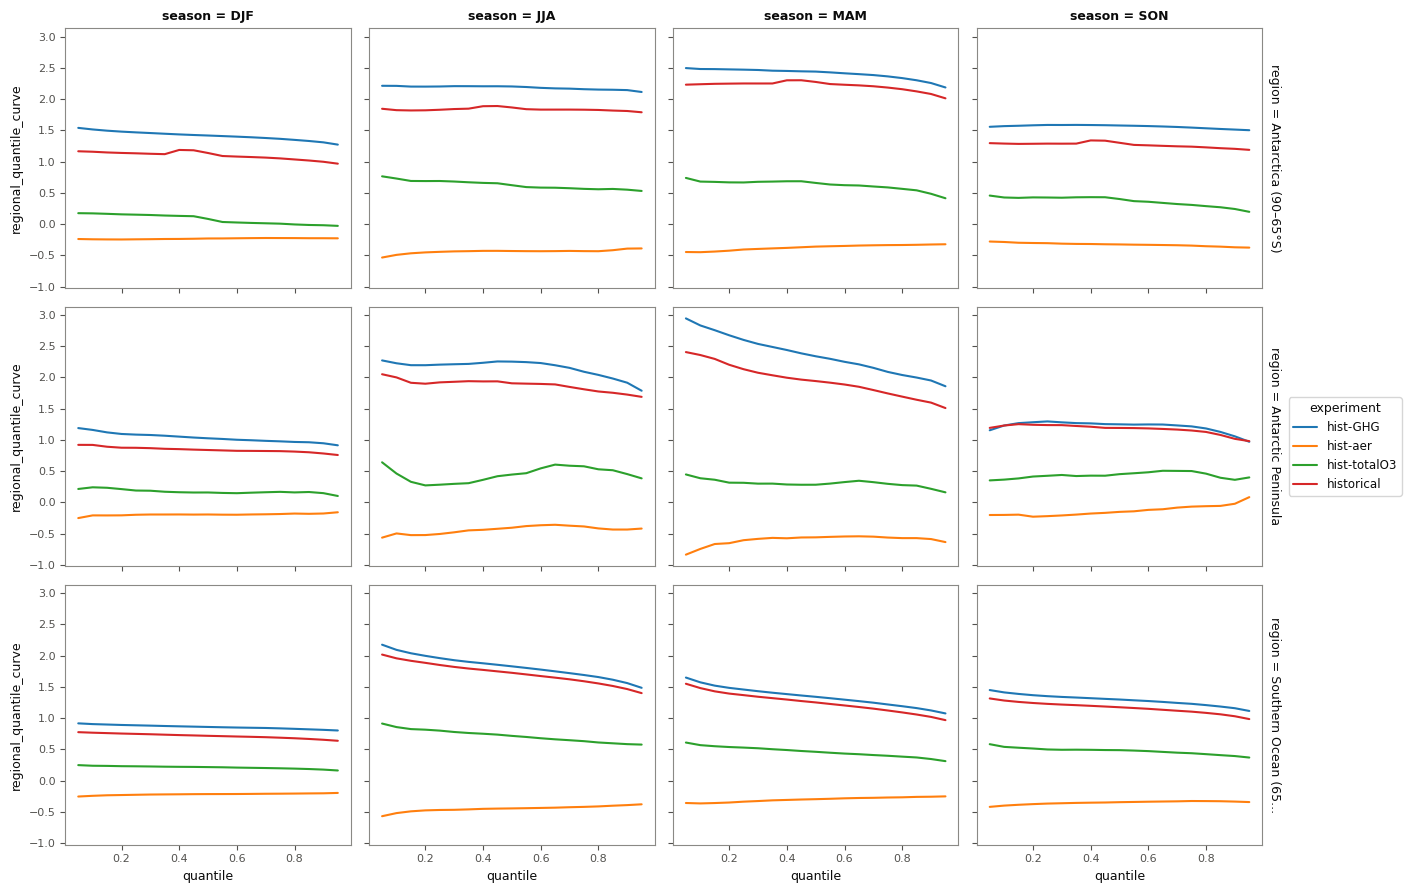

In [305]:
#(t): Quick look: DEMO_MODEL's regional quantile curves, one line per experiment
regional_quantile_curve_da.sel(model=DEMO_MODEL).plot.line(x='quantile', hue='experiment', row='region', col='season');

## 2. Probability Ratios

**The event.** A warm season is one warmer than hist-nat's 95th percentile, and a cold season one colder than its 5th percentile: seasons hist-nat itself has a 5% chance of. The percentiles come from hist-nat's final $L$ years, members and years pooled, the same years as the experiment's:

$$
T^{\mathrm{warm}} = Q_{1 - c}\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right), \qquad
T^{\mathrm{cold}} = Q_{c}\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right),
$$

with hist-nat's chance $c = 5\%$; $c = 10\%$ (its 90th and 10th percentiles) checks it (`CHANCES`). Rarer events are left out on purpose: with $P_{\mathrm{nat}}$ that small, the ratio rests on a handful of seasons.

**The ratio.** The chance of the event is the share of an ensemble's member-years beyond the threshold, member by member and then averaged, $P = \frac{1}{M}\sum_m \frac{1}{L}\sum_y \mathbb{1}\left[x_{m,y} > T^{\mathrm{warm}}\right]$ (below $T^{\mathrm{cold}}$ for a cold season), and

$$
\mathrm{PR} = \frac{P_{\mathrm{exp}}}{P_{\mathrm{nat}}},
$$

so PR = 2 means the forcing doubles the chance and PR = 1/2 halves it.

**Uncertainty.** A bootstrap of whole members: each trial draws as many members as each ensemble has, with replacement, and recalculates both chances against the *same* thresholds, so it asks how well the ensembles pin down the chance of one defined event. A ratio is significant where the central $1 - \alpha$ of its trials is clear of 1.

Section 3 then asks how much of the ratio the shift of the mean alone gives.

First the steps at the demonstration point, then everywhere, then for the regional means.

### At the demonstration point

In [306]:
#(t): The quantile each threshold sits at, on (tail, chance): 1 - chance for warm, the chance for cold
pr_levels_da = pr.threshold_levels(CHANCES)

In [ ]:
#(t): hist-nat's thresholds at the demonstration point, from its final WINDOW years (First Look), members and years pooled
demo_thresholds_da = pr.thresholds(demo_histnat_final_da, pr_levels_da)

In [308]:
#(t): Each member's share of its years beyond them: DEMO_EXPERIMENT's
demo_experiment_exceedance_da = pr.member_exceedance(demo_experiment_final_da, demo_thresholds_da)

In [309]:
#(t): and hist-nat's
demo_histnat_exceedance_da = pr.member_exceedance(demo_histnat_final_da, demo_thresholds_da)

In [310]:
#(t): The chances, averaged over the members: DEMO_EXPERIMENT's
demo_p_experiment_da = demo_experiment_exceedance_da.mean('member')

In [311]:
#(t): and hist-nat's (about the chance, by construction)
demo_p_histnat_da = demo_histnat_exceedance_da.mean('member')

In [312]:
#(t): The probability ratio
demo_pr_da = demo_p_experiment_da / demo_p_histnat_da
demo_pr_da

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
2.438 2.037 0.02903 0.05861
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [313]:
#(t): The numbers side by side
pd.DataFrame({
    'threshold': demo_thresholds_da.to_series(),
    'P hist-nat': demo_p_histnat_da.to_series(),
    f'P {DEMO_EXPERIMENT}': demo_p_experiment_da.to_series(),
    'PR': demo_pr_da.to_series(),
}).round(3)

threshold  P hist-nat  P historical     PR
tail chance                                            
warm 0.05       -2.173        0.05         0.123  2.438
     0.10       -2.678        0.10         0.204  2.037
cold 0.05       -7.284        0.05         0.001  0.029
     0.10       -6.903        0.10         0.006  0.059

In [314]:
#(t): The bootstrap: the mean of DEMO_EXPERIMENT's members drawn with replacement, in each trial (seed 1)
demo_p_experiment_trials_da = pr.bootstrap_member_mean(demo_experiment_exceedance_da, n_trials=DEMO_TRIALS, seed=1)

In [315]:
#(t): How pr.bootstrap_member_mean draws members with replacement, as weights (pr.resample_weights): trial k's row is how
#(t): often each member was drawn, over the number drawn
# Example: 4 members, and a trial draws members [2, 0, 2, 3]. Member 2 is drawn twice, members 0 and 3 once and member 1
# never, so the row is [1, 0, 2, 1] / 4 = [0.25, 0, 0.5, 0.25]. The row times the members' chances, added up, is the mean
# of the 4 drawn, member 2 counted twice. Every trial is then one matrix product (stats.weighted_member_sums).
demo_resample_weights_arr = pr.resample_weights(demo_experiment_exceedance_da.sizes['member'], DEMO_TRIALS,
                                                np.random.default_rng(1))

In [316]:
#(t): Check: trial 0's chance of a warm season from its row of weights, and from pr.bootstrap_member_mean (seed 1, the
#(t): same draws)
demo_warm_chances_da = demo_experiment_exceedance_da.sel(tail='warm', chance=CHANCES[0])
(float(demo_resample_weights_arr[0] @ demo_warm_chances_da.values),
 float(demo_p_experiment_trials_da.isel(trial=0).sel(tail='warm', chance=CHANCES[0])))

(0.12014652014652014, 0.12014652014652016)

In [317]:
#(t): hist-nat's (seed 0)
demo_p_histnat_trials_da = pr.bootstrap_member_mean(demo_histnat_exceedance_da, n_trials=DEMO_TRIALS, seed=0)

In [318]:
#(t): Every trial's ratio
demo_pr_trials_da = demo_p_experiment_trials_da / demo_p_histnat_trials_da

In [319]:
#(t): Its central 1 - ALPHA: the ratio is significant where it is clear of 1
demo_pr_bounds_da = demo_pr_trials_da.quantile([ALPHA / 2, 1 - ALPHA / 2], dim='trial')
demo_pr_bounds_da.to_series().unstack('quantile').round(2)

quantile     0.025  0.975
tail chance              
warm 0.05     1.83   3.38
     0.10     1.65   2.60
cold 0.05     0.00   0.08
     0.10     0.02   0.10

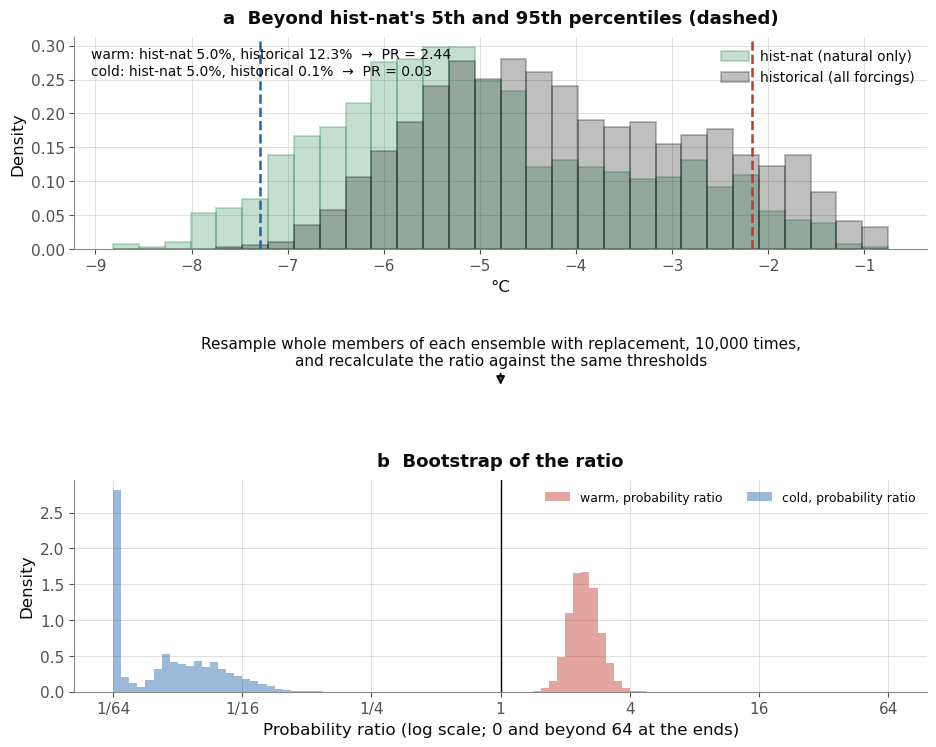

In [320]:
#(t): The probability ratio of a warm and a cold season, step by step: a) the two ensembles' final years, hist-nat's
#(t): two percentiles (dashed) and how often each ensemble goes beyond them; b) the bootstrap's ratios, each tail
warm_percentile, cold_percentile = methods.percentile_words(CHANCES[0])
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 8.5))
    ax_a, flow_axes, _, ax_b = methods.schematic_axes(fig, with_trials=False)
    methods.plot_thresholds(demo_experiment_final_da, demo_histnat_final_da, demo_thresholds_da.sel(chance=CHANCES[0]),
                            DEMO_EXPERIMENT, ax=ax_a)
    ax_a.set_title(f"a  Beyond hist-nat's {cold_percentile} and {warm_percentile} percentiles (dashed)", pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')
    methods.plot_flow(f"Resample whole members of each ensemble with replacement, "
                      f"{demo_pr_trials_da.sizes['trial']:,} times,\nand recalculate the ratio against the same "
                      f"thresholds", flow_axes[0])
    methods.plot_ratio_trials(demo_pr_trials_da.sel(chance=CHANCES[0]), 'probability ratio', ax=ax_b, alpha=0.45,
                              histtype='stepfilled')
    ax_b.set_title('b  Bootstrap of the ratio', pad=10)
    ax_b.set_xlabel('Probability ratio (log scale; 0 and beyond 64 at the ends)')
    ax_b.set_ylabel('Density');

### Everywhere

The same steps at every grid point. The thresholds come from hist-nat alone, so they are made once per model (one function mapped over the hist-nat nodes) and given to every experiment of that model.

In [ ]:
#(t): hist-nat's final WINDOW years in every model (lesfmip_final_tree: above)
pr_hist_nat_final_tree = lesfmip_final_tree.match('*/hist-nat')

In [322]:
pr_levels_da

<xarray.DataArray 'level' (tail: 2, chance: 2)> Size: 32B
0.95 0.9 0.05 0.1
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1

In [323]:
pr.thresholds?

Signature: pr.thresholds(counterfactual, levels, dims=('member', 'year'))
Docstring:
hist-nat's value at each level, its members and years pooled.

Args:
    counterfactual (xr.Dataset | xr.DataArray): hist-nat over the years compared, on (member, year, ...).
    levels (xr.DataArray): ``threshold_levels`` output, on (tail, chance).
    dims (Sequence[str]): The dims pooled (those present).

Returns:
    The same type, on (tail, chance, ...).
File:      ~/ExtAnt-initial/extant/probability_ratio.py
Type:      function

In [324]:
%%time
#(t): Its thresholds, members and years pooled, on (model, tail, chance, season, lat, lon)
pr_thresholds_ds = datatree.reduce_to_dataset(pr_hist_nat_final_tree, partial(pr.thresholds, levels=pr_levels_da))
pr_thresholds_ds = pr_thresholds_ds.sel(experiment='hist-nat', drop=True).compute()

CPU times: user 57.9 ms, sys: 2.89 ms, total: 60.8 ms
Wall time: 230 ms


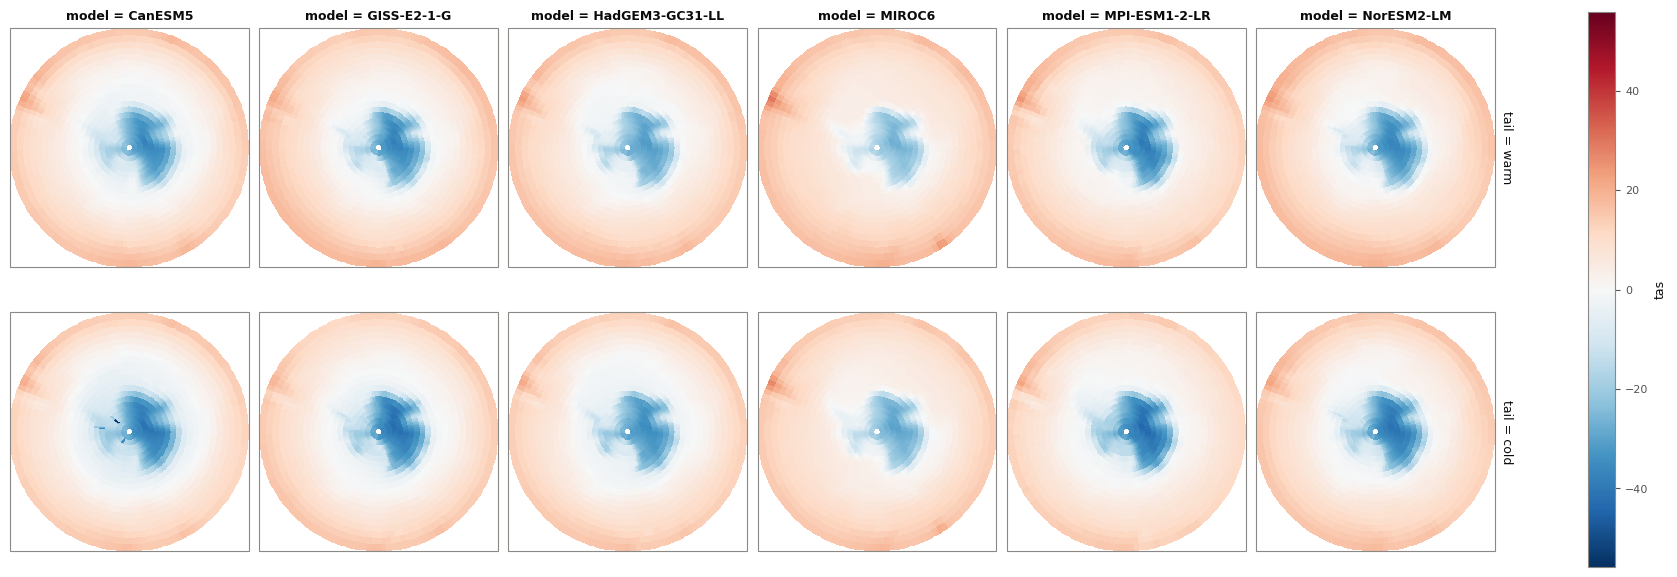

In [325]:
pr_thresholds_ds.tas.sel(chance=0.05, season='DJF').plot(row='tail', col='model',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [326]:
#(t): The same thresholds for every experiment of a model, as a tree shaped like lesfmip_final_tree
pr_thresholds_tree = datatree.dataset_to_tree(pr_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS),
                                              like=lesfmip_final_tree)

In [327]:
pr_thresholds_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
│   └── Group: /GISS-E2-1-G/hist-totalO3
│           Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * tail     (tail) <U4 32B 'warm' 'cold'
│             * chance   (chance) float64 16B 0.05 0.1
│           Data variables:
│               tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│

In [328]:
#(t): Each member's share of its years beyond them, every experiment (hist-nat's own gives the counterfactual)
pr_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, lesfmip_final_tree, pr_thresholds_tree)

In [329]:
%%time
#(t): The chances: every experiment's, averaged over its members
pr_p_ds = datatree.reduce_to_dataset(pr_exceedance_tree, lambda ds: ds.mean('member')).compute()

CPU times: user 115 ms, sys: 13.2 ms, total: 128 ms
Wall time: 1.92 s


In [330]:
pr_p_ds

<xarray.Dataset> Size: 11MB
Dimensions:     (model: 6, experiment: 5, lon: 144, season: 4, lat: 20,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 11MB ...

In [331]:
#(t): hist-nat's own chance: the counterfactual
pr_p_counterfactual_ds = pr_p_ds.sel(experiment='hist-nat', drop=True)

In [332]:
#(t): The probability ratios (hist-nat against itself left out)
pr_ratio_ds = (pr_p_ds / pr_p_counterfactual_ds).drop_sel(experiment='hist-nat')

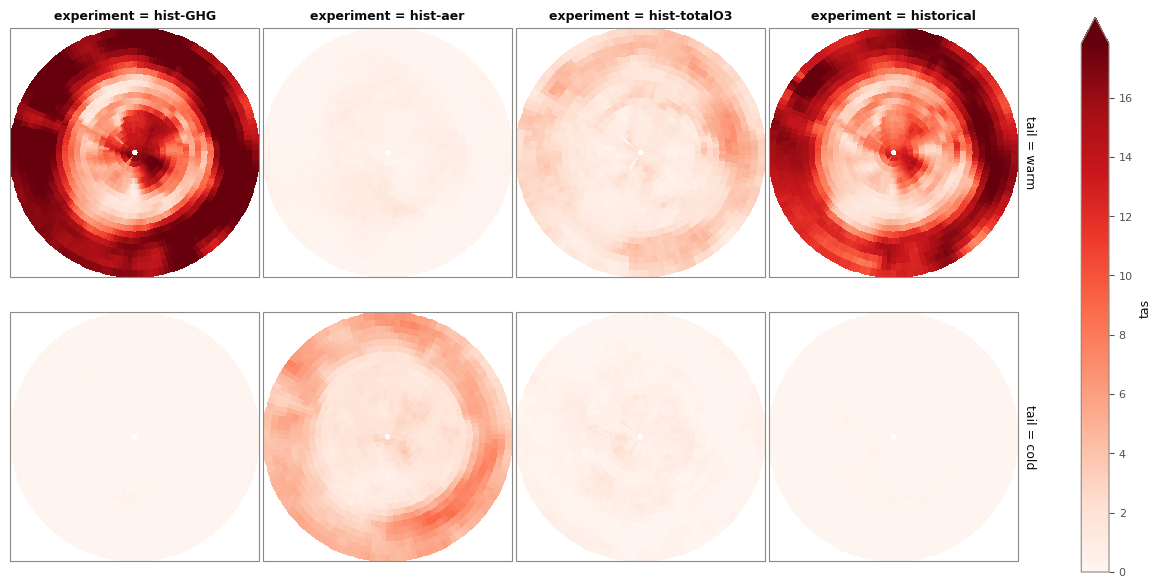

In [333]:
pr_ratio_ds.tas.sel(chance=0.05, season='DJF', model='CanESM5').plot(row='tail', col='experiment', robust=True, cmap='Reds',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [334]:
# .sel(chance=0.05, season='DJF').plot(row='tail', col='model',
#                                              subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [335]:
#(t): The bootstrap: every experiment's members (seed 1), lazily, on (model, experiment, trial, ...)
pr_p_trials_tree = pr_exceedance_tree.map_over_datasets(partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_p_trials_ds = datatree.tree_to_dataset(pr_p_trials_tree, dims=['model', 'experiment'])

In [336]:
#(t): hist-nat's members (seed 0): the counterfactual
pr_p_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_exceedance_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [337]:
#(t): Every trial's ratio (lazy: only its quantiles are computed)
pr_trials_da = (pr_p_trials_ds / pr_p_counterfactual_trials_ds)[VARIABLE.name].drop_sel(experiment='hist-nat')

In [338]:
%%time
#(t): Its central 1 - ALPHA
pr_bounds_da = nan_quantile(pr_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 42.6 ms, sys: 22.8 ms, total: 65.4 ms
Wall time: 6.97 s


In [339]:
#(t): The probability ratios in one Dataset, laid out as notebook plot_06 opens it
pr_ds = xr.Dataset({
    'threshold': pr_thresholds_ds[VARIABLE.name],
    'p_counterfactual': pr_p_counterfactual_ds[VARIABLE.name],
    'p_factual': pr_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': pr_ratio_ds[VARIABLE.name],
    'pr_lower': pr_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': pr_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (pr_bounds_da.isel(quantile=0, drop=True) > 1) | (pr_bounds_da.isel(quantile=1, drop=True) < 1),
})
pr_ds

<xarray.Dataset> Size: 41MB
Dimensions:           (model: 6, lon: 144, lat: 20, season: 4, tail: 2,
                       chance: 2, experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon               (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * lat               (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (lat, lon, season, tail, chance, model) float64 2MB -25...
    p_counterfactual  (tail, lat, lon, season, chance, model) float64 2MB 0.0...
    p_factual         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr                (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_lower          (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_upper          (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_significant    (tail, lat, lon, season, chance, model, experiment) bool 1MB ...

In [340]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_path = RESULTS_DIR / 'probability_ratio.zarr'
pr_ds.to_zarr(probability_ratio_path, mode='w')
probability_ratio_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio.zarr')

In [341]:
#(t): Its value at the demonstration point: the same ratios as step by step above (the bounds from fewer trials)
pr_ds[['pr', 'pr_lower', 'pr_upper']].sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(2)

pr  pr_lower  pr_upper    model    lon   lat season  experiment
tail chance                                                                   
warm 0.05    2.44      1.81      3.40  CanESM5 -180.0 -75.0    DJF  historical
     0.10    2.04      1.65      2.61  CanESM5 -180.0 -75.0    DJF  historical
cold 0.05    0.03      0.00      0.08  CanESM5 -180.0 -75.0    DJF  historical
     0.10    0.06      0.03      0.10  CanESM5 -180.0 -75.0    DJF  historical

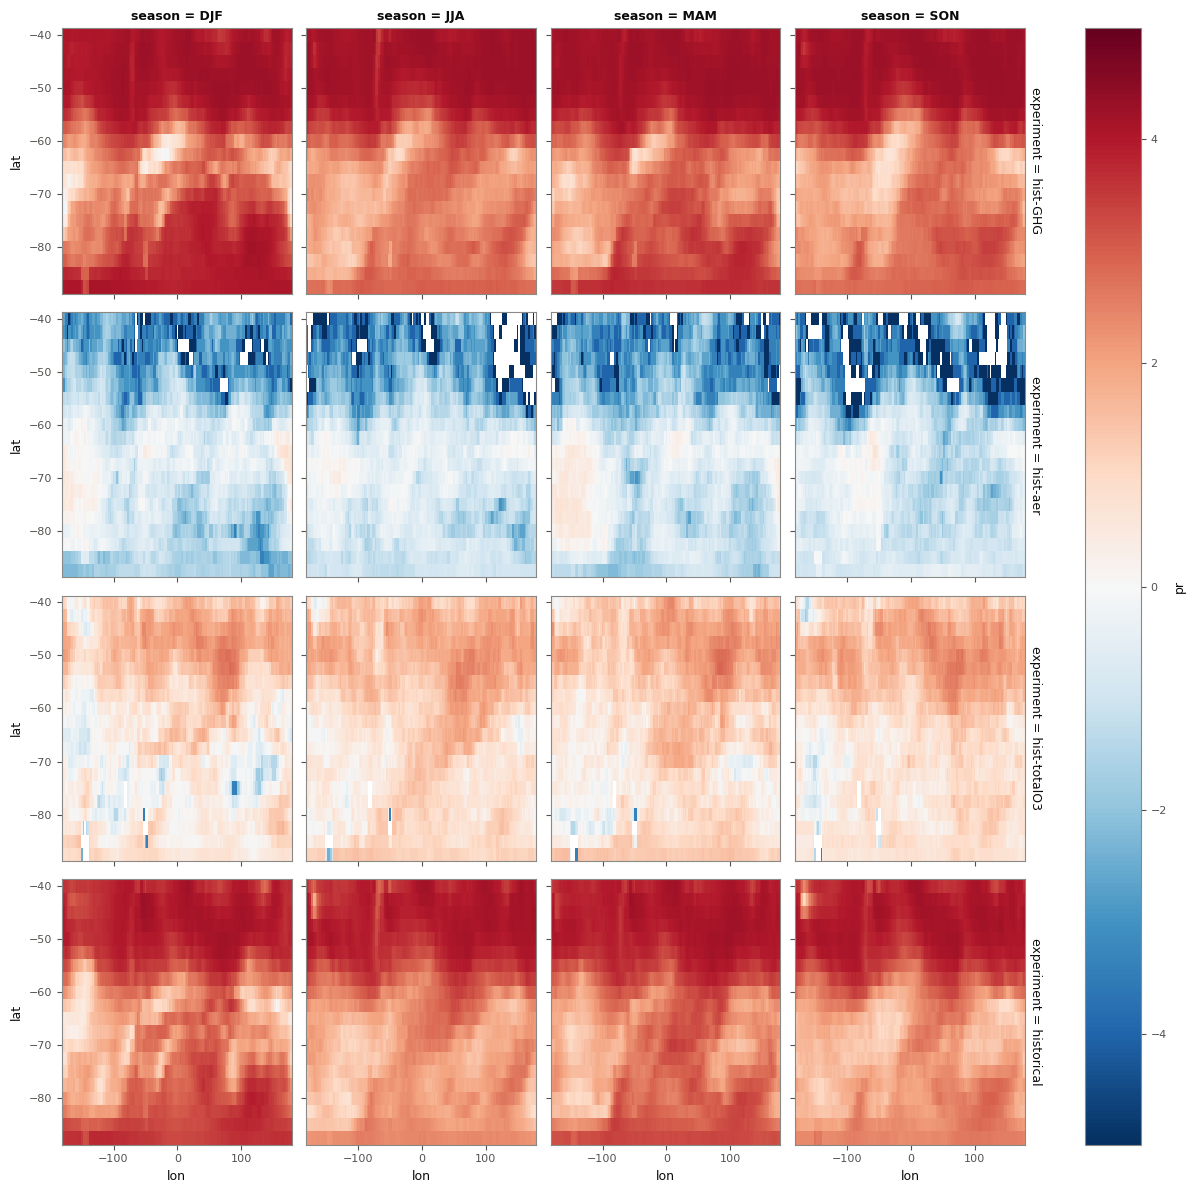

In [342]:
#(t): Quick look: DEMO_MODEL's warm ratio, log2 (1 doubles the chance), experiments down and seasons across
np.log2(pr_ds['pr'].sel(model=DEMO_MODEL, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

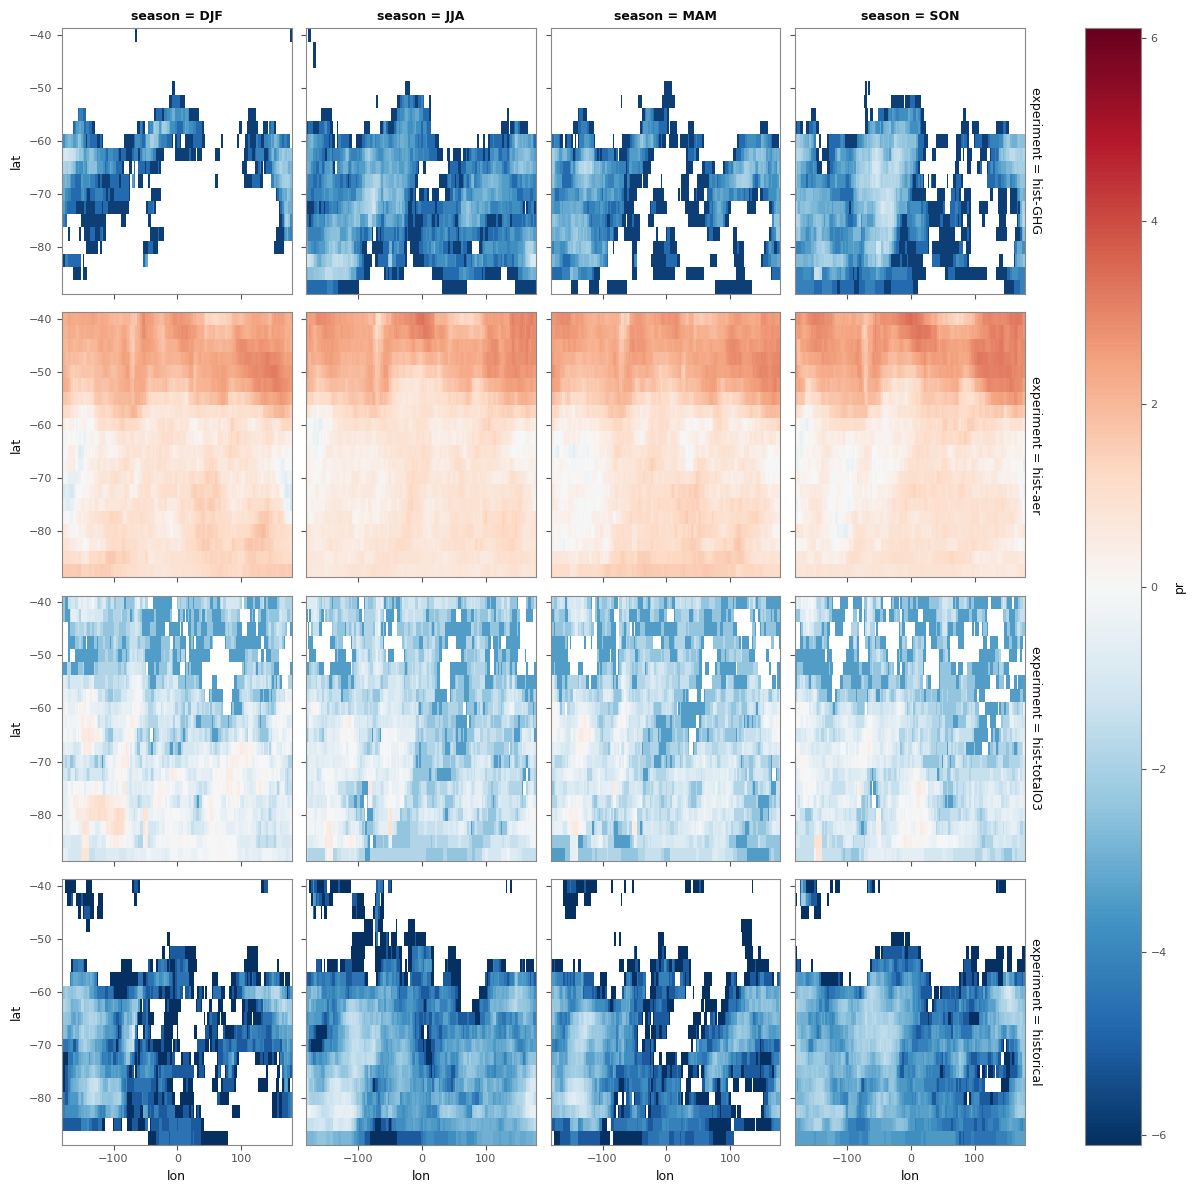

In [343]:
#(t): and the cold one
np.log2(pr_ds['pr'].sel(model=DEMO_MODEL, tail='cold', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### For the regional means

The same steps on the regional means of section 1: the thresholds are hist-nat's regional percentiles, so these are the ratios for a warm or cold season *of the region as a whole*, not the regional average of the local ratios.

In [ ]:
#(t): The final WINDOW years of the regional means (section 1)
regional_final_tree = regional_season_tree.isel(year=slice(-WINDOW, None))

In [345]:
#(t): hist-nat's regional thresholds, on (model, tail, chance, region, season)
regional_thresholds_ds = datatree.reduce_to_dataset(regional_final_tree.match('*/hist-nat'),
                                                    partial(pr.thresholds, levels=pr_levels_da))
regional_thresholds_ds = regional_thresholds_ds.sel(experiment='hist-nat', drop=True)

In [346]:
#(t): The same thresholds for every experiment of a model
regional_thresholds_tree = datatree.dataset_to_tree(
    regional_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS), like=regional_final_tree)

In [347]:
#(t): Each member's share of its years beyond them
regional_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, regional_final_tree, regional_thresholds_tree)

In [348]:
#(t): The chances
regional_p_ds = datatree.reduce_to_dataset(regional_exceedance_tree, lambda ds: ds.mean('member'))

In [349]:
regional_p_counterfactual_ds = regional_p_ds.sel(experiment='hist-nat', drop=True)
regional_p_counterfactual_ds

<xarray.Dataset> Size: 3kB
Dimensions:  (model: 6, tail: 2, region: 3, season: 4, chance: 2)
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1
Data variables:
    tas      (tail, region, season, chance, model) float64 2kB 0.05048 ... 0....

In [350]:
#(t): The bootstrap: every experiment's members (seed 1)
regional_p_trials_ds = datatree.reduce_to_dataset(
    regional_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))

In [351]:
#(t): hist-nat's (seed 0)
regional_p_counterfactual_trials_ds = datatree.reduce_to_dataset(
    regional_exceedance_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [352]:
#(t): Every trial's ratio
regional_pr_trials_ds = regional_p_trials_ds / regional_p_counterfactual_trials_ds
regional_pr_trials_da = regional_pr_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [353]:
#(t): Its central 1 - ALPHA
regional_pr_bounds_da = nan_quantile(regional_pr_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial')

In [354]:
#(t): The regional probability ratios in one Dataset, laid out as notebook plot_06 opens it
regional_pr_ds = xr.Dataset({
    'threshold': regional_thresholds_ds[VARIABLE.name],
    'p_counterfactual': regional_p_counterfactual_ds[VARIABLE.name],
    'p_factual': regional_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': (regional_p_ds / regional_p_counterfactual_ds)[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_lower': regional_pr_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': regional_pr_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (regional_pr_bounds_da.isel(quantile=0, drop=True) > 1)
                      | (regional_pr_bounds_da.isel(quantile=1, drop=True) < 1),
})
regional_pr_ds

<xarray.Dataset> Size: 43kB
Dimensions:           (model: 6, season: 4, region: 3, tail: 2, chance: 2,
                       experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region            (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern...
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (region, season, tail, chance, model) float64 2kB -12.4...
    p_counterfactual  (tail, region, season, chance, model) float64 2kB 0.050...
    p_factual         (tail, region, season, chance, model, experiment) float64 9kB ...
    pr                (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_lower          (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_upper          (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_significant    (tail, region, season, chance, model, experiment) bool 1kB ...

In [355]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_regional_path = RESULTS_DIR / 'probability_ratio_regional.zarr'
regional_pr_ds.to_zarr(probability_ratio_regional_path, mode='w')
probability_ratio_regional_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_regional.zarr')

In [356]:
#(t): The numbers for the first region, hist-nat's chance CHANCES[0]: every model, experiment, tail and season
regional_pr_ds[['pr', 'pr_lower', 'pr_upper']].sel(
    region=list(REGIONS)[0], chance=CHANCES[0]).to_dataframe().unstack('season').round(2)

pr                      pr_lower         \
season                               DJF    JJA    MAM    SON      DJF    JJA   
tail model           experiment                                                 
warm CanESM5         hist-GHG      18.38  14.87  18.51  14.74    14.12  10.86   
                     hist-aer       0.13   0.25   0.50   0.28     0.03   0.08   
                     hist-totalO3   1.13   2.74   3.58   2.55     0.53   1.55   
                     historical    14.57  11.97  17.39  11.29    11.23   8.76   
     GISS-E2-1-G     hist-GHG      11.17  10.75  11.81  10.16     8.26   7.63   
                     hist-aer       1.21   1.21   1.48   1.35     0.77   0.69   
                     hist-totalO3   1.31   3.43   1.81   2.81     0.84   2.20   
                     historical     6.94   8.41   9.09   8.68     5.01   5.88   
     HadGEM3-GC31-LL hist-GHG      11.38  11.43  14.42  10.63     6.37   6.00   
                     hist-aer       2.75   4.74   4.62   4.43     1.34   2.28   
                     hist-totalO3   0.59   0.93   1.07   1.31     0.26   0.32   
                     historical     3.90   3.36   5.09   4.71     2.12   1.67   
     MIROC6          hist-GHG       6.13   4.83   4.58   3.42     4.62   3.62   
                     hist-aer       0.28   0.09   0.47   0.85     0.07   0.00   
                     hist-totalO3   0.09   0.57   0.28   0.47     0.00   0.26   
                     historical     4.75   4.23   4.45   3.58     3.65   3.25   
     MPI-ESM1-2-LR   hist-GHG      12.19   9.56  13.28   9.50     8.69   6.73   
                     hist-aer       0.97   0.69   1.03   0.91     0.59   0.39   
                     hist-totalO3   1.97   2.47   2.06   3.03     1.28   1.55   
                     historical    10.07  10.00  11.12   9.76     7.15   7.13   
     NorESM2-LM      hist-GHG       3.40   2.68   4.40   3.32     2.40   1.82   
                     hist-aer       0.64   0.24   0.04   0.28     0.30   0.06   
                     hist-totalO3   0.32   1.20   0.87   0.64     0.12   0.72   
                     historical     2.01   3.25   3.57   3.57     1.39   2.29   
cold CanESM5         hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       2.92   2.20   2.58   2.67     2.18   1.48   
                     hist-totalO3   0.47   0.00   0.00   0.19     0.17   0.00   
                     historical     0.00   0.03   0.00   0.00     0.00   0.00   
     GISS-E2-1-G     hist-GHG       0.00   0.02   0.00   0.00     0.00   0.00   
                     hist-aer       1.88   1.97   1.80   1.16     1.25   1.18   
                     hist-totalO3   1.19   0.36   0.67   0.17     0.79   0.18   
                     historical     0.00   0.05   0.03   0.03     0.00   0.00   
     HadGEM3-GC31-LL hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       1.37   1.16   1.00   0.81     0.83   0.60   
                     hist-totalO3   1.85   1.18   1.18   0.59     1.26   0.74   
                     historical     0.07   0.07   0.00   0.00     0.00   0.00   
     MIROC6          hist-GHG       0.04   0.21   0.04   0.34     0.00   0.07   
                     hist-aer       2.36   2.26   1.60   1.89     1.51   1.62   
                     hist-totalO3   3.30   0.85   1.42   2.17     2.37   0.26   
                     historical     0.13   0.21   0.23   0.26     0.04   0.09   
     MPI-ESM1-2-LR   hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       1.06   1.53   1.03   0.91     0.66   1.00   
                     hist-totalO3   0.22   0.34   0.41   0.19     0.09   0.16   
                     historical     0.00   0.00   0.02   0.00     0.00   0.00   
     NorESM2-LM      hist-GHG       0.00   0.24   0.04   0.08     0.00   0.04   
                     hist-aer       2.96   3.48   4.72   3.08     2.00   2.18   
                     hist-totalO3   2.62   0.87   1.38   1.01     1.7

### By SAM phase

The same events, a season warmer than hist-nat's 95th percentile or colder than its 5th over all its seasons (`pr_thresholds_ds`), and their chance among the seasons of one SAM phase: how much more often a forcing gives a warm or a cold season when the SAM is in that phase. hist-nat's own chance differs between the phases (a warm season is likelier in one phase than in another), so each ratio is against hist-nat's chance in the same phase.

Members have different numbers of seasons in a phase, so the chance is pooled, every season counted once: the seasons beyond the threshold over all the seasons in the phase,

$$
P = \frac{\sum_m \#\{y \in \text{phase} : x_{m,y} > T\}}{\sum_m \#\{y \in \text{phase}\}}.
$$

The bootstrap resamples whole members, as above, and draws the same members for both counts (the same seed), so each trial's chance is pooled the same way.

In [ ]:
#(t): The final WINDOW years (lesfmip_final_tree: above) of the nodes with an index
lesfmip_sam_final_tree = lesfmip_final_tree.filter(lambda node: node.relative_to(lesfmip_final_tree) in sam_both_paths)

In [226]:
#(t): Split into the three phases: NaN outside each phase's seasons, on (phase, member, year, season, lat, lon)
lesfmip_phase_tree = xr.map_over_datasets(sam.by_phase, lesfmip_sam_final_tree, sam_final_masks_tree)

In [357]:
#(t): hist-nat's thresholds (above) on the nodes with an index
pr_sam_thresholds_tree = pr_thresholds_tree.filter(lambda node: node.relative_to(pr_thresholds_tree) in sam_both_paths)

In [ ]:
#(t): How many of each member's seasons in each phase are beyond them (lesfmip_phase_tree: above)
pr_phase_beyond_tree = xr.map_over_datasets(pr.member_beyond, lesfmip_phase_tree, pr_sam_thresholds_tree)

In [359]:
#(t): and how many seasons each member has in each phase
pr_phase_count_tree = lesfmip_phase_tree.count('year')

In [360]:
%%time
#(t): The seasons beyond the thresholds, added up over the members, every experiment
pr_phase_beyond_ds = datatree.reduce_to_dataset(pr_phase_beyond_tree, lambda ds: ds.sum('member')).compute()

CPU times: user 213 ms, sys: 39.4 ms, total: 252 ms
Wall time: 2.89 s


In [361]:
%%time
#(t): and the seasons in each phase
pr_phase_count_ds = datatree.reduce_to_dataset(pr_phase_count_tree, lambda ds: ds.sum('member')).compute()

CPU times: user 569 ms, sys: 62.2 ms, total: 631 ms
Wall time: 1.35 s


In [362]:
#(t): The chances: the one over the other
pr_phase_p_ds = pr_phase_beyond_ds / pr_phase_count_ds

In [363]:
#(t): hist-nat's own chance in each phase: the counterfactual
pr_phase_p_counterfactual_ds = pr_phase_p_ds.sel(experiment='hist-nat', drop=True)

In [364]:
#(t): The probability ratios in each phase (hist-nat against itself left out)
pr_phase_ratio_ds = (pr_phase_p_ds / pr_phase_p_counterfactual_ds).drop_sel(experiment='hist-nat')

In [365]:
#(t): The bootstrap: every experiment's members (seed 1), their counts beyond the thresholds, lazily
pr_phase_beyond_trials_tree = pr_phase_beyond_tree.map_over_datasets(
    partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_phase_beyond_trials_ds = datatree.tree_to_dataset(pr_phase_beyond_trials_tree, dims=['model', 'experiment'])

In [366]:
#(t): and their counts of seasons, with the same draws (seed 1)
pr_phase_count_trials_tree = pr_phase_count_tree.map_over_datasets(
    partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_phase_count_trials_ds = datatree.tree_to_dataset(pr_phase_count_trials_tree, dims=['model', 'experiment'])

In [367]:
#(t): Every trial's chance
pr_phase_p_trials_ds = pr_phase_beyond_trials_ds / pr_phase_count_trials_ds

In [368]:
#(t): hist-nat's members (seed 0): their counts beyond the thresholds
pr_phase_beyond_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_phase_beyond_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [ ]:
#(t): and their counts of seasons (seed 0; the shift-only ratio, section 3, uses these too)
pr_phase_count_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_phase_count_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [370]:
#(t): Every trial's counterfactual chance
pr_phase_p_counterfactual_trials_ds = pr_phase_beyond_counterfactual_trials_ds / pr_phase_count_counterfactual_trials_ds

In [371]:
#(t): Every trial's ratio (lazy: only its quantiles are computed)
pr_phase_trials_da = ((pr_phase_p_trials_ds / pr_phase_p_counterfactual_trials_ds)[VARIABLE.name]
                      .drop_sel(experiment='hist-nat'))

In [372]:
%%time
#(t): Its central 1 - ALPHA
pr_phase_bounds_da = nan_quantile(pr_phase_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 90.1 ms, sys: 69.2 ms, total: 159 ms
Wall time: 21.7 s


In [373]:
#(t): The probability ratios by SAM phase in one Dataset, laid out as pr_ds with a phase dim
sam_pr_ds = xr.Dataset({
    'threshold': pr_thresholds_ds[VARIABLE.name],
    'p_counterfactual': pr_phase_p_counterfactual_ds[VARIABLE.name],
    'p_factual': pr_phase_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': pr_phase_ratio_ds[VARIABLE.name],
    'pr_lower': pr_phase_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': pr_phase_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (pr_phase_bounds_da.isel(quantile=0, drop=True) > 1)
                      | (pr_phase_bounds_da.isel(quantile=1, drop=True) < 1),
})
sam_pr_ds

<xarray.Dataset> Size: 118MB
Dimensions:           (model: 6, lon: 144, lat: 20, season: 4, tail: 2,
                       chance: 2, phase: 3, experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon               (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * lat               (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * phase             (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (lat, lon, season, tail, chance, model) float64 2MB -25...
    p_counterfactual  (tail, lat, lon, season, phase, chance, model) float64 7MB ...
    p_factual         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr                (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_lower          (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_upper          (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_significant    (tail, lat, lon, season, phase, chance, model, experiment) bool 3MB ...

In [374]:
#(t): Saved for notebooks plot_03 to plot_06
sam_probability_ratio_path = RESULTS_DIR / 'sam_probability_ratio.zarr'
sam_pr_ds.to_zarr(sam_probability_ratio_path, mode='w')
sam_probability_ratio_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio.zarr')

In [375]:
#(t): Its value at the demonstration point, every phase
sam_pr_ds[['p_counterfactual', 'p_factual', 'pr', 'pr_lower', 'pr_upper']].sel(
    **DEMO_SEL, experiment=DEMO_EXPERIMENT, chance=CHANCES[0]).sel(**DEMO_LATLON).to_dataframe().round(2)

p_counterfactual  p_factual    pr  pr_lower  pr_upper    model  \
tail phase                                                                      
warm negative              0.05       0.06  1.22      0.47      2.89  CanESM5   
     neutral               0.06       0.11  1.77      1.17      2.81  CanESM5   
     positive              0.04       0.14  3.22      1.99      5.96  CanESM5   
cold negative              0.05       0.01  0.13      0.00      0.46  CanESM5   
     neutral               0.03       0.00  0.00      0.00      0.00  CanESM5   
     positive              0.07       0.00  0.02      0.00      0.06  CanESM5   

                 lon   lat season  chance  experiment  
tail phase                                             
warm negative -180.0 -75.0    DJF    0.05  historical  
     neutral  -180.0 -75.0    DJF    0.05  historical  
     positive -180.0 -75.0    DJF    0.05  historical  
cold negative -180.0 -75.0    DJF    0.05  historical  
     neutral  -180.0 -75.0    DJF    0.05  historical  
     positive -180.0 -75.0    DJF    0.05  historical

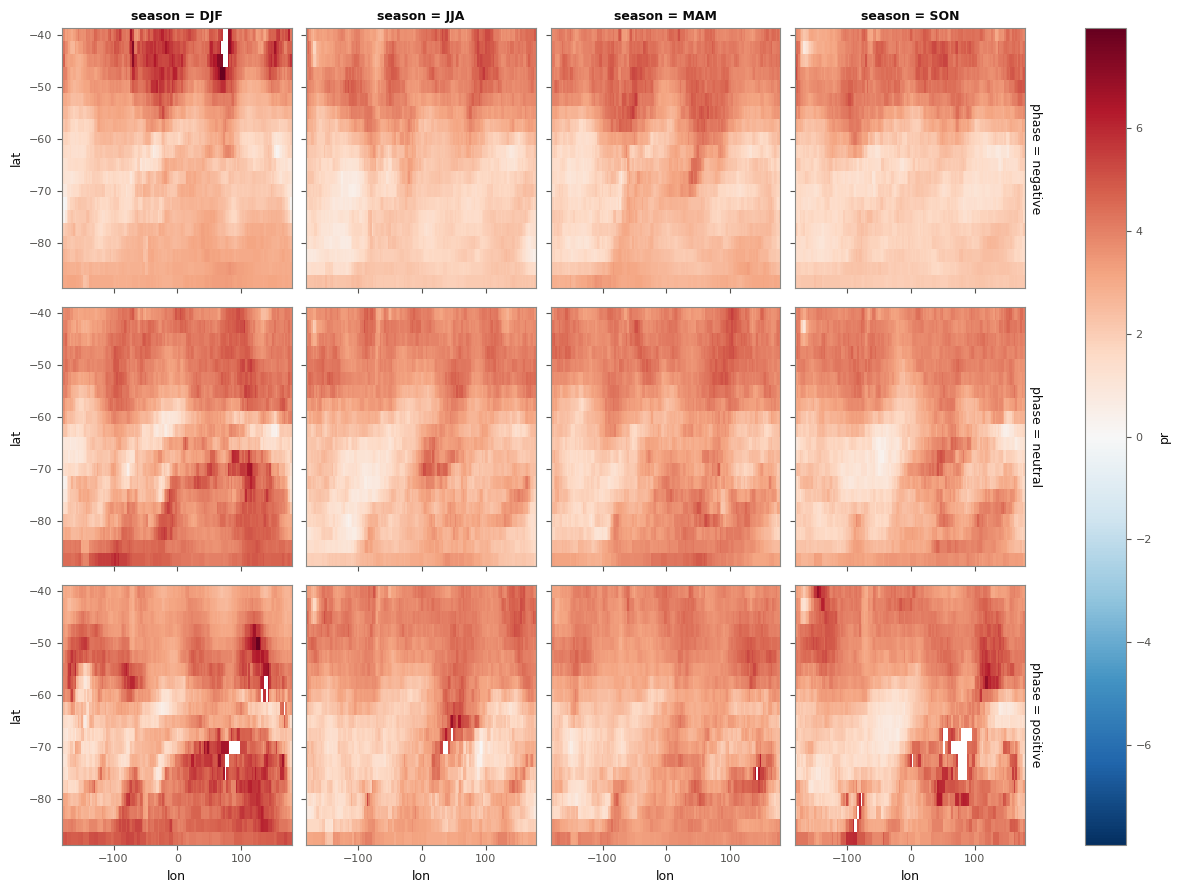

In [376]:
#(t): Quick look: DEMO_MODEL's warm ratio in each phase, log2, DEMO_EXPERIMENT
np.log2(sam_pr_ds['pr'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 3. Shift-Only Ratio

A probability ratio above 1 can come from the whole distribution moving warmer (the mean shifting), from it getting wider or narrower, or from both. The **shift-only ratio** is the ratio the shift alone would give. hist-nat's own seasons are each moved by the experiment's change in the mean, $\Delta = \bar{x}^{\mathrm{exp}} - \bar{x}^{\mathrm{nat}}$ (both over the final $L$ years), and counted against section 2's thresholds:

$$
P^{\text{shift only}}_{\mathrm{exp}} = P\left(x^{\mathrm{nat}} + \Delta > T\right) = P\left(x^{\mathrm{nat}} > T - \Delta\right),
\qquad
\mathrm{PR}^{\text{shift only}} = \frac{P^{\text{shift only}}_{\mathrm{exp}}}{P_{\mathrm{nat}}}.
$$

Moving every season up by $\Delta$ is the same as moving the threshold down by $\Delta$, and that is how it is calculated: hist-nat's seasons against the **moved thresholds** $T - \Delta$ (`pr_shift_only_thresholds_ds`), one set for each experiment.

**An example.** hist-nat goes above its warm threshold 5% of the time and hist-GHG 15%, so PR = 3. hist-nat's seasons moved up by hist-GHG's warming go above it 12% of the time, so the shift-only ratio is 2.4. The warming alone gives most of the 3; the rest comes from hist-GHG's distribution also getting wider. A ratio below its shift-only ratio means a narrowing held it back, which matters most for cold seasons.

**Uncertainty.** The bootstrap of section 2. The shift-only chance and hist-nat's own chance are both made from hist-nat's members, so they are resampled with the same draws (the same seed, 0), and their ratio keeps its pairing.

### At the demonstration point

In [377]:
#(t): The change in the mean at the point: the experiment's final-years mean minus hist-nat's
demo_shift_da = demo_experiment_final_da.mean() - demo_histnat_final_da.mean()

In [378]:
#(t): hist-nat's thresholds moved down by it: hist-nat's seasons beyond these are the seasons the experiment
#(t): would have beyond the real thresholds, had its distribution only shifted
demo_shift_only_thresholds_da = demo_thresholds_da - demo_shift_da

In [379]:
#(t): The share of each hist-nat member's years beyond the moved thresholds
demo_shift_only_exceedance_da = pr.member_exceedance(demo_histnat_final_da, demo_shift_only_thresholds_da)

In [380]:
#(t): averaged over the members: the shift-only chance
demo_p_shift_only_da = demo_shift_only_exceedance_da.mean('member')

In [ ]:
#(t): The shift-only ratio: against hist-nat's own chance (section 2)
demo_pr_shift_only_da = demo_p_shift_only_da / demo_p_histnat_da
demo_pr_shift_only_da

In [ ]:
#(t): The numbers side by side, with section 2's
pd.DataFrame({
    'P hist-nat': demo_p_histnat_da.to_series(),
    'P hist-nat, shifted': demo_p_shift_only_da.to_series(),
    f'P {DEMO_EXPERIMENT}': demo_p_experiment_da.to_series(),
    'PR, shift only': demo_pr_shift_only_da.to_series(),
    'PR': demo_pr_da.to_series(),
}).round(3)

In [383]:
#(t): The bootstrap: hist-nat's shift-only shares, with the same draws of hist-nat's members as its own chance
#(t): (seed 0)
demo_p_shift_only_trials_da = pr.bootstrap_member_mean(demo_shift_only_exceedance_da, n_trials=DEMO_TRIALS, seed=0)

In [384]:
#(t): Every trial's shift-only ratio
demo_shift_only_trials_da = demo_p_shift_only_trials_da / demo_p_histnat_trials_da

In [385]:
#(t): Its central 1 - ALPHA
demo_shift_only_bounds_da = demo_shift_only_trials_da.quantile([ALPHA / 2, 1 - ALPHA / 2], dim='trial')
demo_shift_only_bounds_da.to_series().unstack('quantile').round(2)

quantile     0.025  0.975
tail chance              
warm 0.05     2.41   3.78
     0.10     1.80   2.40
cold 0.05     0.00   0.12
     0.10     0.07   0.20

In [386]:
#(t): hist-nat's seasons, every one moved by the shift: what the moved thresholds stand in for
demo_histnat_shifted_da = demo_histnat_final_da + demo_shift_da
demo_histnat_shifted_da

<xarray.DataArray 'tas' (member: 50, year: 21)> Size: 4kB
-3.092 -2.794 -2.475 -5.049 -5.129 -4.037 ... -6.683 -4.539 -4.811 -4.266 -3.426
Coordinates:
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013

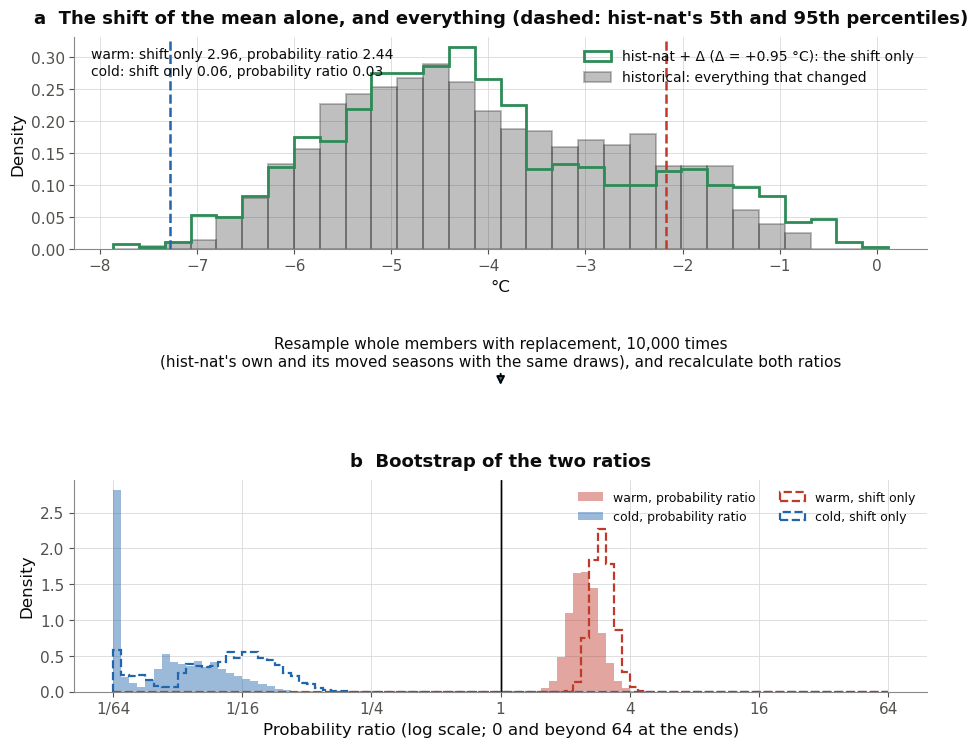

In [387]:
#(t): The shift-only ratio, step by step: a) hist-nat's seasons, every one moved by the change in the mean, against
#(t): the experiment itself and hist-nat's thresholds; b) the bootstrap's ratios, both, each tail
warm_percentile, cold_percentile = methods.percentile_words(CHANCES[0])
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 8.5))
    ax_a, flow_axes, _, ax_b = methods.schematic_axes(fig, with_trials=False)
    methods.plot_shift_only(demo_experiment_final_da, demo_histnat_final_da, demo_thresholds_da.sel(chance=CHANCES[0]),
                            demo_shift_da, DEMO_EXPERIMENT, units=VARIABLE.units, ax=ax_a)
    ax_a.set_title(f"a  The shift of the mean alone, and everything (dashed: hist-nat's {cold_percentile} and "
                   f"{warm_percentile} percentiles)", pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')
    methods.plot_flow(f"Resample whole members with replacement, {demo_shift_only_trials_da.sizes['trial']:,} times\n"
                      "(hist-nat's own and its moved seasons with the same draws), and recalculate both ratios",
                      flow_axes[0])
    methods.plot_ratio_trials(demo_pr_trials_da.sel(chance=CHANCES[0]), 'probability ratio', ax=ax_b, alpha=0.45,
                              histtype='stepfilled')
    methods.plot_ratio_trials(demo_shift_only_trials_da.sel(chance=CHANCES[0]), 'shift only', ax=ax_b,
                              histtype='step', lw=1.6, ls='--')
    ax_b.set_title('b  Bootstrap of the two ratios', pad=10)
    ax_b.set_xlabel('Probability ratio (log scale; 0 and beyond 64 at the ends)')
    ax_b.set_ylabel('Density');

### Everywhere

The same steps at every grid point, against section 2's thresholds (`pr_thresholds_ds`) and hist-nat's own chances and bootstrap (`pr_p_counterfactual_ds`, `pr_p_counterfactual_trials_ds`).

In [ ]:
#(t): Every experiment's ensemble mean over its final years, as notebook calc_02b saved it (its section 1)
final_mean_path = RESULTS_DIR / 'final_mean.zarr'
final_mean_path

In [ ]:
final_mean_ds = xr.open_zarr(final_mean_path).load()

In [ ]:
#(t): The change in the mean of every experiment, from those final-years means (0 for hist-nat)
pr_shift_ds = final_mean_ds - final_mean_ds.sel(experiment='hist-nat')

In [389]:
#(t): hist-nat's thresholds moved down by it, one set per experiment
pr_shift_only_thresholds_ds = pr_thresholds_ds - pr_shift_ds

In [390]:
#(t): As a tree shaped like lesfmip_final_tree
pr_shift_only_thresholds_tree = datatree.dataset_to_tree(pr_shift_only_thresholds_ds, like=lesfmip_final_tree)

In [ ]:
#(t): hist-nat's members (hist_nat_final_tree: above) against each experiment's moved thresholds
pr_shift_only_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, hist_nat_final_tree,
                                                     pr_shift_only_thresholds_tree)

In [392]:
%%time
#(t): The shift-only chances, averaged over hist-nat's members
pr_p_shift_only_ds = datatree.reduce_to_dataset(pr_shift_only_exceedance_tree, lambda ds: ds.mean('member')).compute()

CPU times: user 120 ms, sys: 23.1 ms, total: 143 ms
Wall time: 2.36 s


In [ ]:
#(t): The shift-only ratios: against hist-nat's own chance (section 2)
pr_ratio_shift_only_ds = (pr_p_shift_only_ds / pr_p_counterfactual_ds).drop_sel(experiment='hist-nat')

In [394]:
#(t): The bootstrap: hist-nat's shift-only shares, with the same draws as its own chance (seed 0)
pr_p_shift_only_trials_ds = datatree.reduce_to_dataset(
    pr_shift_only_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
)

In [395]:
#(t): Every trial's shift-only ratio (lazy: only its quantiles are computed)
pr_shift_only_trials_ds = pr_p_shift_only_trials_ds / pr_p_counterfactual_trials_ds
pr_shift_only_trials_da = pr_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [396]:
%%time
#(t): Its central 1 - ALPHA
pr_shift_only_bounds_da = nan_quantile(pr_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 42.7 ms, sys: 26.1 ms, total: 68.8 ms
Wall time: 5.76 s


In [397]:
#(t): The shift-only ratios in one Dataset, laid out as notebook plot_06 opens it
pr_shift_only_ds = xr.Dataset({
    'shift': pr_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': pr_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': pr_ratio_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': pr_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': pr_shift_only_bounds_da.isel(quantile=1, drop=True),
})
pr_shift_only_ds

<xarray.Dataset> Size: 36MB
Dimensions:              (model: 6, experiment: 4, lon: 144, season: 4,
                          lat: 20, tail: 2, chance: 2)
Coordinates:
  * model                (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment           (experiment) object 32B 'hist-GHG' ... 'historical'
  * lon                  (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season               (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                  (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * tail                 (tail) <U4 32B 'warm' 'cold'
  * chance               (chance) float64 16B 0.05 0.1
Data variables:
    shift                (lat, lon, season, model, experiment) float32 1MB 2....
    p_shift_only         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only        (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only_lower  (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only_upper  (tail, lat, lon, season, chance, model, experiment) float64 9MB ...

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_shift_only_path = RESULTS_DIR / 'probability_ratio_shift_only.zarr'
pr_shift_only_ds.to_zarr(probability_ratio_shift_only_path, mode='w')
probability_ratio_shift_only_path

In [ ]:
#(t): Its value at the demonstration point: the same ratios as step by step above (the bounds from fewer trials)
pr_shift_only_ds[['pr_shift_only', 'pr_shift_only_lower', 'pr_shift_only_upper']].sel(
    **DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(2)

In [ ]:
#(t): Quick look: DEMO_MODEL's warm shift-only ratio, log2, experiments down and seasons across
np.log2(pr_shift_only_ds['pr_shift_only'].sel(model=DEMO_MODEL, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### For the regional means

The same steps on the regional means, against section 2's regional thresholds (`regional_thresholds_ds`).

In [ ]:
#(t): Every experiment's final-years ensemble mean in each region
regional_final_mean_ds = datatree.reduce_to_dataset(regional_final_tree, lambda ds: ds.mean(['member', 'year']))

In [ ]:
#(t): The change in each region's mean (0 for hist-nat)
regional_shift_ds = regional_final_mean_ds - regional_final_mean_ds.sel(experiment='hist-nat')

In [ ]:
#(t): The regional thresholds (section 2) moved down by it
regional_shift_only_thresholds_ds = regional_thresholds_ds - regional_shift_ds

In [ ]:
#(t): As a tree shaped like regional_final_tree
regional_shift_only_thresholds_tree = datatree.dataset_to_tree(regional_shift_only_thresholds_ds,
                                                               like=regional_final_tree)

In [ ]:
#(t): Each experiment's model's hist-nat, in a tree shaped like regional_final_tree
regional_hist_nat_final_tree = datatree.hist_nat_like(regional_final_tree)

In [ ]:
#(t): hist-nat's members against each experiment's moved thresholds: the shift-only shares
regional_shift_only_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, regional_hist_nat_final_tree,
                                                           regional_shift_only_thresholds_tree)

In [ ]:
#(t): The shift-only chances
regional_p_shift_only_ds = datatree.reduce_to_dataset(regional_shift_only_exceedance_tree,
                                                      lambda ds: ds.mean('member'))

In [ ]:
#(t): The shift-only ratios: against hist-nat's own chance (section 2)
regional_pr_shift_only_ds = (regional_p_shift_only_ds / regional_p_counterfactual_ds).drop_sel(
    experiment='hist-nat')

In [ ]:
#(t): The bootstrap: hist-nat's shift-only shares with the same draws as its own chance (seed 0)
regional_p_shift_only_trials_ds = datatree.reduce_to_dataset(
    regional_shift_only_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0))

In [ ]:
#(t): Every trial's shift-only ratio
regional_shift_only_trials_ds = regional_p_shift_only_trials_ds / regional_p_counterfactual_trials_ds
regional_shift_only_trials_da = regional_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [ ]:
#(t): Its central 1 - ALPHA
regional_shift_only_bounds_da = nan_quantile(regional_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial')

In [ ]:
#(t): The regional shift-only ratios in one Dataset, laid out as notebook plot_06 opens it
regional_shift_only_ds = xr.Dataset({
    'shift': regional_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': regional_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': regional_pr_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': regional_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': regional_shift_only_bounds_da.isel(quantile=1, drop=True),
})
regional_shift_only_ds

In [413]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_shift_only_regional_path = RESULTS_DIR / 'probability_ratio_shift_only_regional.zarr'
regional_shift_only_ds.to_zarr(probability_ratio_shift_only_regional_path, mode='w')
probability_ratio_shift_only_regional_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only_regional.zarr')

In [ ]:
#(t): The numbers for the first region, hist-nat's chance CHANCES[0], next to section 2's ratios
xr.merge([regional_pr_ds[['pr']], regional_shift_only_ds[['pr_shift_only']]]).sel(
    region=list(REGIONS)[0], chance=CHANCES[0]).to_dataframe().unstack('season').round(2)

### By SAM phase

The shift-only ratio in each SAM phase: hist-nat's seasons in the phase, each moved by the change in the mean in that phase (notebook calc_02b, section 1, *By SAM phase*, worked out again below), against the same thresholds, pooled as in section 2's SAM subsection and over hist-nat's own chance in the phase. Where the probability ratio in a phase is bigger than its shift-only ratio, the width or shape in that phase has made the event more likely still.

In [227]:
%%time
#(t): The mean in each phase, members and years pooled, every experiment, on (model, experiment, phase, season, lat, lon)
phase_mean_ds = datatree.reduce_to_dataset(lesfmip_phase_tree, lambda ds: ds.mean(['member', 'year'])).compute()

CPU times: user 101 ms, sys: 9.27 ms, total: 110 ms
Wall time: 931 ms


In [ ]:
#(t): The change in the mean in each phase (above), 0 for hist-nat
pr_phase_shift_ds = phase_mean_ds - phase_mean_ds.sel(experiment='hist-nat')

In [416]:
#(t): hist-nat's thresholds moved down by it, one set per experiment and phase
pr_phase_shift_only_thresholds_ds = pr_thresholds_ds - pr_phase_shift_ds

In [417]:
#(t): As a tree shaped like lesfmip_phase_tree
pr_phase_shift_only_thresholds_tree = datatree.dataset_to_tree(pr_phase_shift_only_thresholds_ds,
                                                               like=lesfmip_phase_tree)

In [418]:
#(t): Each experiment's model's hist-nat in each phase, in a tree shaped like lesfmip_phase_tree
hist_nat_phase_tree = datatree.hist_nat_like(lesfmip_phase_tree)

In [419]:
#(t): How many of hist-nat's seasons in each phase are beyond each experiment's moved thresholds, member by member
pr_phase_shift_only_beyond_tree = xr.map_over_datasets(pr.member_beyond, hist_nat_phase_tree,
                                                       pr_phase_shift_only_thresholds_tree)

In [420]:
%%time
#(t): Added up over hist-nat's members
pr_phase_shift_only_beyond_ds = datatree.reduce_to_dataset(pr_phase_shift_only_beyond_tree,
                                                           lambda ds: ds.sum('member')).compute()

CPU times: user 210 ms, sys: 57.1 ms, total: 267 ms
Wall time: 2.13 s


In [ ]:
#(t): The shift-only chances: over all of hist-nat's seasons in the phase (section 2, by SAM phase)
pr_phase_p_shift_only_ds = pr_phase_shift_only_beyond_ds / pr_phase_count_ds.sel(experiment='hist-nat', drop=True)

In [422]:
#(t): The shift-only ratios: against hist-nat's own chance in the phase
pr_phase_ratio_shift_only_ds = (pr_phase_p_shift_only_ds / pr_phase_p_counterfactual_ds).drop_sel(experiment='hist-nat')

In [423]:
#(t): The bootstrap: hist-nat's counts beyond the moved thresholds, with the same draws as its own chance (seed 0)
pr_phase_shift_only_beyond_trials_ds = datatree.reduce_to_dataset(
    pr_phase_shift_only_beyond_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
)

In [424]:
#(t): Every trial's shift-only chance, over the same trial's count of hist-nat's seasons in the phase
pr_phase_p_shift_only_trials_ds = pr_phase_shift_only_beyond_trials_ds / pr_phase_count_counterfactual_trials_ds

In [425]:
#(t): Every trial's shift-only ratio (lazy: only its quantiles are computed)
pr_phase_shift_only_trials_ds = pr_phase_p_shift_only_trials_ds / pr_phase_p_counterfactual_trials_ds
pr_phase_shift_only_trials_da = pr_phase_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [426]:
%%time
#(t): Its central 1 - ALPHA
pr_phase_shift_only_bounds_da = nan_quantile(pr_phase_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2],
                                             'trial').compute()

CPU times: user 65.7 ms, sys: 61.8 ms, total: 128 ms
Wall time: 13.9 s


In [427]:
#(t): The shift-only ratios by SAM phase in one Dataset, laid out as pr_shift_only_ds with a phase dim
sam_pr_shift_only_ds = xr.Dataset({
    'shift': pr_phase_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': pr_phase_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': pr_phase_ratio_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': pr_phase_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': pr_phase_shift_only_bounds_da.isel(quantile=1, drop=True),
})
sam_pr_shift_only_ds

<xarray.Dataset> Size: 109MB
Dimensions:              (model: 6, experiment: 4, lon: 144, season: 4,
                          lat: 20, phase: 3, tail: 2, chance: 2)
Coordinates:
  * model                (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment           (experiment) object 32B 'hist-GHG' ... 'historical'
  * lon                  (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season               (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                  (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * phase                (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail                 (tail) <U4 32B 'warm' 'cold'
  * chance               (chance) float64 16B 0.05 0.1
Data variables:
    shift                (lat, lon, season, phase, model, experiment) float32 3MB ...
    p_shift_only         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only        (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only_lower  (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only_upper  (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...

In [428]:
#(t): Saved for notebooks plot_03 to plot_06
sam_probability_ratio_shift_only_path = RESULTS_DIR / 'sam_probability_ratio_shift_only.zarr'
sam_pr_shift_only_ds.to_zarr(sam_probability_ratio_shift_only_path, mode='w')
sam_probability_ratio_shift_only_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio_shift_only.zarr')

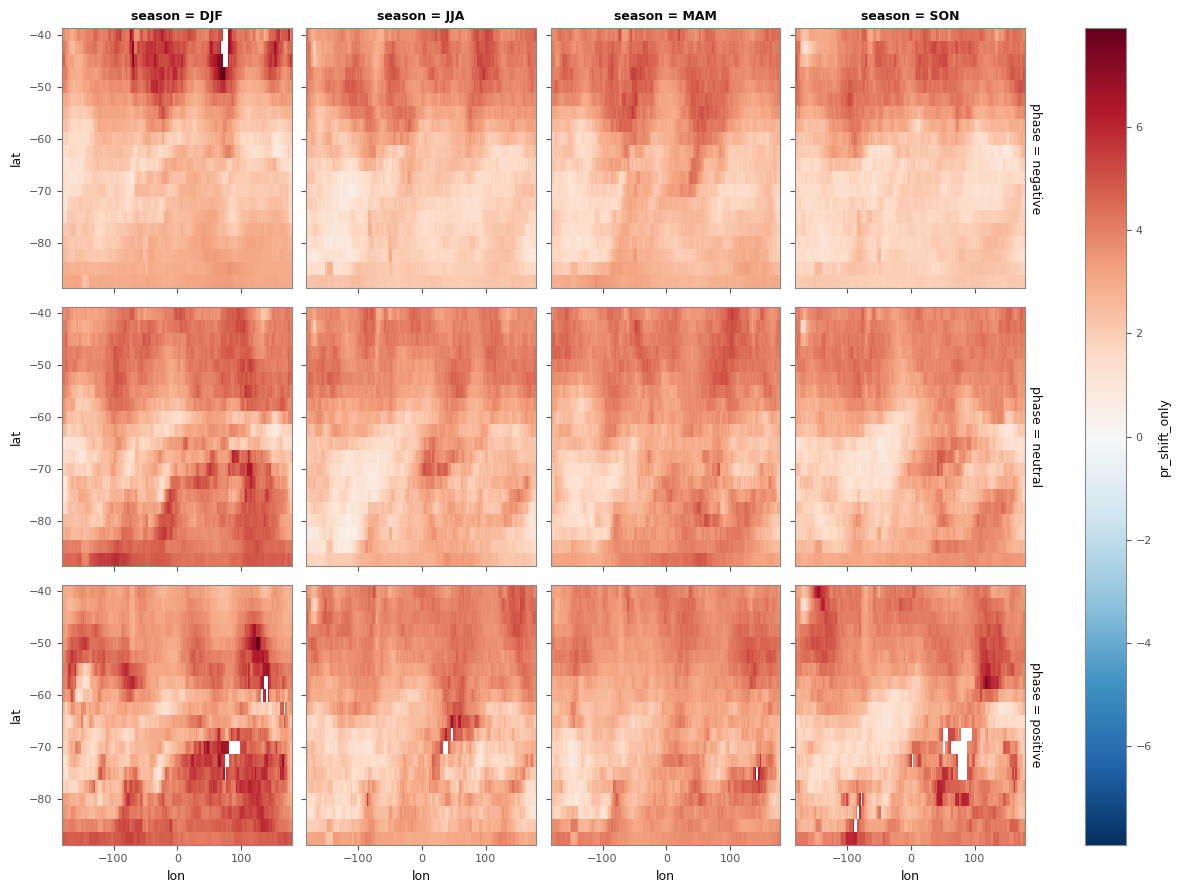

In [429]:
#(t): Quick look: DEMO_MODEL's warm shift-only ratio in each phase, log2, DEMO_EXPERIMENT
np.log2(sam_pr_shift_only_ds['pr_shift_only'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT, tail='warm',
                                                  chance=CHANCES[0])).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## Saved Results

Everything this notebook saved, in `RESULTS_DIR`:

In [437]:
#(t): Everything this notebook saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_